In [1]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# machine Learning

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
#from sklearn.file import joblib

In [2]:
df = pd.read_csv("bank.csv", sep=';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
4516,33,services,married,secondary,no,-333,yes,no,cellular,30,jul,329,5,-1,0,unknown,no
4517,57,self-employed,married,tertiary,yes,-3313,yes,yes,unknown,9,may,153,1,-1,0,unknown,no
4518,57,technician,married,secondary,no,295,no,no,cellular,19,aug,151,11,-1,0,unknown,no
4519,28,blue-collar,married,secondary,no,1137,no,no,cellular,6,feb,129,4,211,3,other,no
4520,44,entrepreneur,single,tertiary,no,1136,yes,yes,cellular,3,apr,345,2,249,7,other,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [5]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [6]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [7]:
df ['y'].value_counts()

y
no     4000
yes     521
Name: count, dtype: int64

In [8]:
df ['age'].value_counts()

age
34    231
32    224
31    199
36    188
33    186
     ... 
76      2
81      1
86      1
87      1
84      1
Name: count, Length: 67, dtype: int64

In [9]:
df ['marital'].value_counts()

marital
married     2797
single      1196
divorced     528
Name: count, dtype: int64

In [10]:
(df['education'] == "unknown").mean() * 100

np.float64(4.13625304136253)

In [11]:
df['y'] = df['y'].map({"yes":1, "no":0})
print(df["y"].value_counts())

y
0    4000
1     521
Name: count, dtype: int64


In [12]:
df['education'].value_counts()

education
secondary    2306
tertiary     1350
primary       678
unknown       187
Name: count, dtype: int64

In [13]:
most_common = df['marital'].mode()[0]
df['marital'] = df['marital'].replace('unknown', most_common)
print(df['marital'].value_counts())

marital
married     2797
single      1196
divorced     528
Name: count, dtype: int64


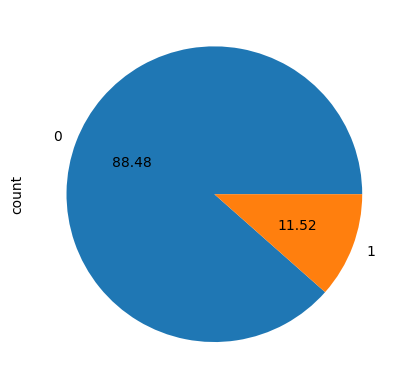

In [14]:
# Using pie chart
df['y'].value_counts().plot(kind='pie', autopct='%.2f')
plt.show()

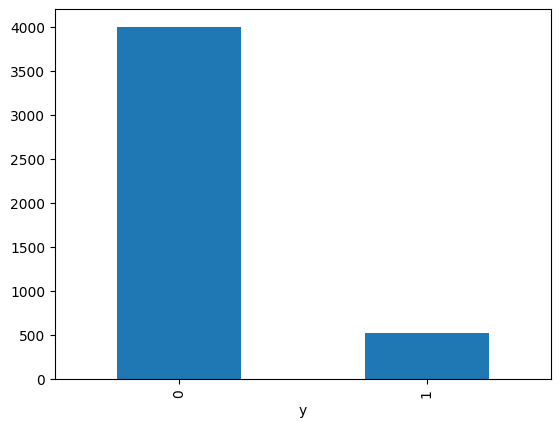

In [15]:
# Using bar chart
df['y'].value_counts().plot(kind='bar')
plt.show()

In [16]:
df = pd.get_dummies(df, drop_first=True)

In [17]:
X = df.drop("y", axis=1)
y = df["y"]

In [18]:
print(X)

      age  balance  day  ...  poutcome_other  poutcome_success  poutcome_unknown
0      30     1787   19  ...           False             False              True
1      33     4789   11  ...           False             False             False
2      35     1350   16  ...           False             False             False
3      30     1476    3  ...           False             False              True
4      59        0    5  ...           False             False              True
...   ...      ...  ...  ...             ...               ...               ...
4516   33     -333   30  ...           False             False              True
4517   57    -3313    9  ...           False             False              True
4518   57      295   19  ...           False             False              True
4519   28     1137    6  ...            True             False             False
4520   44     1136    3  ...            True             False             False

[4521 rows x 42 columns]


In [19]:
print(y)

0       0
1       0
2       0
3       0
4       0
       ..
4516    0
4517    0
4518    0
4519    0
4520    0
Name: y, Length: 4521, dtype: int64


In [20]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [21]:
scalar = StandardScaler()
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)

In [22]:
X_train

array([[-0.67837091, -0.41380412,  0.48996678, ..., -0.21375489,
        -0.17377983,  0.4690128 ],
       [-0.86603026,  0.33457068, -0.23823703, ..., -0.21375489,
        -0.17377983,  0.4690128 ],
       [-0.67837091, -0.12191285, -0.96644085, ..., -0.21375489,
        -0.17377983,  0.4690128 ],
       ...,
       [ 0.4475852 , -0.32021245, -1.20917546, ..., -0.21375489,
        -0.17377983, -2.13213796],
       [ 0.54141487, -0.34997532,  0.61133409, ..., -0.21375489,
        -0.17377983,  0.4690128 ],
       [ 1.5735413 , -0.39695045,  0.36859948, ..., -0.21375489,
        -0.17377983,  0.4690128 ]])

In [23]:
X_test

array([[ 9.16733574e-01, -1.25433624e+00,  1.46090520e+00, ...,
        -2.13754885e-01, -1.73779833e-01,  4.69012803e-01],
       [ 8.22903898e-01,  5.25339911e-01, -1.33054276e+00, ...,
         4.67825565e+00, -1.73779833e-01, -2.13213796e+00],
       [ 8.22903898e-01, -1.42701677e-03, -1.20917546e+00, ...,
        -2.13754885e-01, -1.73779833e-01,  4.69012803e-01],
       ...,
       [ 1.01056325e+00, -3.54278383e-01,  1.70363981e+00, ...,
        -2.13754885e-01, -1.73779833e-01,  4.69012803e-01],
       [-9.59859934e-01,  3.18792770e-01, -1.45191006e+00, ...,
        -2.13754885e-01, -1.73779833e-01,  4.69012803e-01],
       [-1.61666766e+00,  1.10589516e+00, -6.02338942e-01, ...,
        -2.13754885e-01, -1.73779833e-01,  4.69012803e-01]])

In [24]:
# LogisticRegression

log_model = LogisticRegression()
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)
print(accuracy_score(y_test, y_pred_log))
print(confusion_matrix(y_test, y_pred_log))

0.901657458563536
[[789  18]
 [ 71  27]]


In [25]:
# DecisionTree Classifier
tree_model = DecisionTreeClassifier()
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)
print(accuracy_score(y_test, y_pred_tree))
print(confusion_matrix(y_test, y_pred_tree))

0.8895027624309392
[[755  52]
 [ 48  50]]


In [26]:
# RandomForest Classifier

random_model = RandomForestClassifier()
random_model.fit(X_train, y_train)
y_pred_random = random_model.predict(X_test)
print(accuracy_score(y_test, y_pred_random))
print(confusion_matrix(y_test, y_pred_random))

0.901657458563536
[[791  16]
 [ 73  25]]


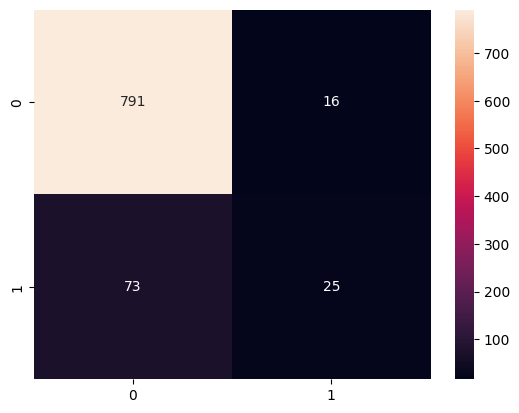

In [27]:
cm = confusion_matrix(y_test, y_pred_random)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

In [28]:
y_pred_prob = log_model.predict_proba(X_test)[:, 1]
y_pred_prob

array([2.13730400e-02, 4.42327340e-01, 3.67426402e-02, 2.19614493e-02,
       2.05427866e-01, 3.38683323e-02, 1.02756278e-01, 2.52296051e-01,
       7.23044798e-02, 2.53465280e-01, 7.52265018e-02, 8.09853289e-02,
       1.41389384e-01, 9.36055609e-01, 2.73969725e-02, 7.21413269e-02,
       3.11505912e-01, 7.59944474e-02, 2.78614843e-02, 7.92278646e-03,
       1.02287085e-02, 5.32634951e-03, 7.23548642e-01, 3.93404575e-02,
       1.84285404e-02, 2.47334178e-02, 3.22654904e-01, 9.15695263e-01,
       4.08951187e-02, 1.62489546e-02, 3.51538848e-02, 4.20284177e-02,
       3.99341065e-03, 2.16718963e-02, 2.61414163e-02, 3.76656417e-02,
       6.96815323e-01, 1.13549090e-02, 4.28450974e-03, 6.39288383e-02,
       2.04291518e-02, 6.37677467e-02, 3.24531993e-01, 4.06669711e-01,
       7.77119500e-02, 3.72410934e-02, 5.15760265e-03, 6.24076295e-02,
       8.37971173e-02, 3.29133794e-02, 3.45944249e-02, 2.01227648e-01,
       3.58528446e-01, 3.60438798e-02, 3.18466551e-02, 1.64960499e-02,
      

In [29]:
from sklearn.metrics import  classification_report
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.92      0.98      0.95       807
           1       0.60      0.28      0.38        98

    accuracy                           0.90       905
   macro avg       0.76      0.63      0.66       905
weighted avg       0.88      0.90      0.88       905



In [30]:
from sklearn.metrics import  classification_report
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

           0       0.94      0.94      0.94       807
           1       0.49      0.51      0.50        98

    accuracy                           0.89       905
   macro avg       0.72      0.72      0.72       905
weighted avg       0.89      0.89      0.89       905



In [31]:
from sklearn.metrics import  classification_report
print(classification_report(y_test, y_pred_random))

              precision    recall  f1-score   support

           0       0.92      0.98      0.95       807
           1       0.61      0.26      0.36        98

    accuracy                           0.90       905
   macro avg       0.76      0.62      0.65       905
weighted avg       0.88      0.90      0.88       905



In [32]:
# LogisticRegression and class_weight = "balanced"
log_model_balanced = LogisticRegression(class_weight="balanced")
log_model_balanced.fit(X_train, y_train)
y_pred_log_balanced = log_model_balanced.predict(X_test)
print(accuracy_score(y_test, y_pred_log_balanced))
print(confusion_matrix(y_test, y_pred_log_balanced))
print(classification_report(y_test, y_pred_log_balanced))

0.8331491712707182
[[672 135]
 [ 16  82]]
              precision    recall  f1-score   support

           0       0.98      0.83      0.90       807
           1       0.38      0.84      0.52        98

    accuracy                           0.83       905
   macro avg       0.68      0.83      0.71       905
weighted avg       0.91      0.83      0.86       905



In [33]:
# DescisionTreeClassifier and class_weight = "balanced"
tree_model_balanced = DecisionTreeClassifier(class_weight="balanced")
tree_model_balanced.fit(X_train, y_train)
y_pred_tree_balanced = tree_model_balanced.predict(X_test)
print(accuracy_score(y_test, y_pred_tree_balanced))
print(confusion_matrix(y_test, y_pred_tree_balanced))
print(classification_report(y_test, y_pred_tree_balanced))

0.8773480662983425
[[757  50]
 [ 61  37]]
              precision    recall  f1-score   support

           0       0.93      0.94      0.93       807
           1       0.43      0.38      0.40        98

    accuracy                           0.88       905
   macro avg       0.68      0.66      0.67       905
weighted avg       0.87      0.88      0.87       905



In [34]:
# RandomForestClassifier and class_weight = "balanced"
random_model_balanced = RandomForestClassifier(class_weight="balanced")
random_model_balanced.fit(X_train, y_train)
y_pred_random_balanced = random_model_balanced.predict(X_test)
print(accuracy_score(y_test, y_pred_random_balanced))
print(confusion_matrix(y_test, y_pred_random_balanced))
print(classification_report(y_test, y_pred_random_balanced))

0.8961325966850828
[[800   7]
 [ 87  11]]
              precision    recall  f1-score   support

           0       0.90      0.99      0.94       807
           1       0.61      0.11      0.19        98

    accuracy                           0.90       905
   macro avg       0.76      0.55      0.57       905
weighted avg       0.87      0.90      0.86       905



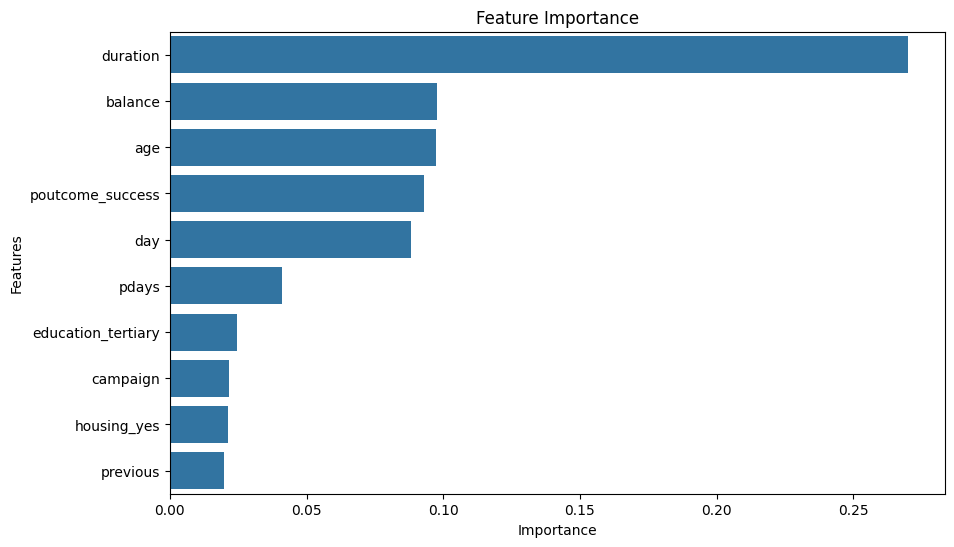

In [35]:
# Get importance from tree model

importances = tree_model.feature_importances_
feature_names = X.columns

# Create DataFrame for visualization
feature_importances_df = pd.DataFrame({'Features':feature_names, 'Importance':importances})
feature_importances_df.sort_values('Importance', ascending = False).head(5)

# plot

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Features', data=feature_importances_df.sort_values('Importance', ascending = False).head(10))
plt.title('Feature Importance')
plt.show()

In [36]:
# Drop y and duration in a dataset
X = df.drop(["y", "duration"], axis=1)
y = df["y"]

# We re-split the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Re-split the data since x has few columns now
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

In [37]:
# Using LogisticRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

log_model_balanced = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model_balanced.fit(X_train_scaled, y_train)
y_pred_log_balanced = log_model_balanced.predict(X_test_scaled)

print("--balanced-- LogisticRegression")
print(accuracy_score(y_test, y_pred_log_balanced))
print(confusion_matrix(y_test, y_pred_log_balanced))
print(classification_report(y_test, y_pred_log_balanced))

--balanced-- LogisticRegression
0.7138121546961326
[[595 212]
 [ 47  51]]
              precision    recall  f1-score   support

           0       0.93      0.74      0.82       807
           1       0.19      0.52      0.28        98

    accuracy                           0.71       905
   macro avg       0.56      0.63      0.55       905
weighted avg       0.85      0.71      0.76       905



In [38]:
# Using RandomForestClassfier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rmb = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
rmb.fit(X_train_scaled, y_train)
y_pred_rmb = log_model_balanced.predict(X_test_scaled)

print("--balanced-- RandomForestClassifier")
print(accuracy_score(y_test, y_pred_rmb))
print(confusion_matrix(y_test, y_pred_rmb))
print(classification_report(y_test, y_pred_rmb))

--balanced-- RandomForestClassifier
0.7138121546961326
[[595 212]
 [ 47  51]]
              precision    recall  f1-score   support

           0       0.93      0.74      0.82       807
           1       0.19      0.52      0.28        98

    accuracy                           0.71       905
   macro avg       0.56      0.63      0.55       905
weighted avg       0.85      0.71      0.76       905



In [39]:
# Using DecisionTree Classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

dtc = DecisionTreeClassifier(random_state=42, class_weight="balanced")
dtc.fit(X_train_scaled, y_train)
y_pred_dtc = dtc.predict(X_test_scaled)

print("--balanced-- DecisionTree Classifier")
print(accuracy_score(y_test, y_pred_dtc))
print(confusion_matrix(y_test, y_pred_dtc))
print(classification_report(y_test, y_pred_dtc))

--balanced-- DecisionTree Classifier
0.8209944751381215
[[719  88]
 [ 74  24]]
              precision    recall  f1-score   support

           0       0.91      0.89      0.90       807
           1       0.21      0.24      0.23        98

    accuracy                           0.82       905
   macro avg       0.56      0.57      0.56       905
weighted avg       0.83      0.82      0.83       905



In [40]:
# How to check for cross validation
from sklearn.model_selection import  cross_val_score
scores = cross_val_score(rmb, X, y, cv=5)

print(scores.mean())
print(scores.std())

0.8902894440913315
0.0019204043474614963


In [41]:
# Get new threshold for the data
y_probs_rf = rmb.predict_proba(X_test_scaled)[:,1]

new_threshold = 0.3
y_pred_tuned = (y_probs_rf >= new_threshold).astype(int)
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.92      0.94      0.93       807
           1       0.44      0.36      0.39        98

    accuracy                           0.88       905
   macro avg       0.68      0.65      0.66       905
weighted avg       0.87      0.88      0.88       905



In [42]:
# To get Hypertunning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced', 'balanced_subsample']
}

rf_random = RandomizedSearchCV(
    estimator = RandomForestClassifier(random_state=42),
    param_distributions = param_dist,
    n_iter = 10,
    cv = 6,
    scoring ="f1",
    verbose = 2,
    random_state = 42,
    n_jobs = -1
)

rf_random.fit(X_train, y_train)

# To get the best version of our model
best_rf = rf_random.best_estimator_

y_pred_best = best_rf.predict(X_test)
print("--- Best Random Forest Settings ---")
print(rf_random.best_params_)
print("--- Best Random Forest Report ---")
print(classification_report(y_test, y_pred_best))

Fitting 6 folds for each of 10 candidates, totalling 60 fits
--- Best Random Forest Settings ---
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 10, 'class_weight': 'balanced_subsample'}
--- Best Random Forest Report ---
              precision    recall  f1-score   support

           0       0.93      0.90      0.91       807
           1       0.33      0.41      0.37        98

    accuracy                           0.85       905
   macro avg       0.63      0.65      0.64       905
weighted avg       0.86      0.85      0.85       905



In [43]:
print("--- Best Random Forest Report ---")
print(classification_report(y_test, y_pred_best))

--- Best Random Forest Report ---
              precision    recall  f1-score   support

           0       0.93      0.90      0.91       807
           1       0.33      0.41      0.37        98

    accuracy                           0.85       905
   macro avg       0.63      0.65      0.64       905
weighted avg       0.86      0.85      0.85       905



C:\Users\Oluwadimimu Adewale\AppData\Local\Temp\ipykernel_7860\3883152451.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='Features', x='Importances', data=feature_importance_df.sort_values('Importances', ascending=False).head(5), palette='viridis')


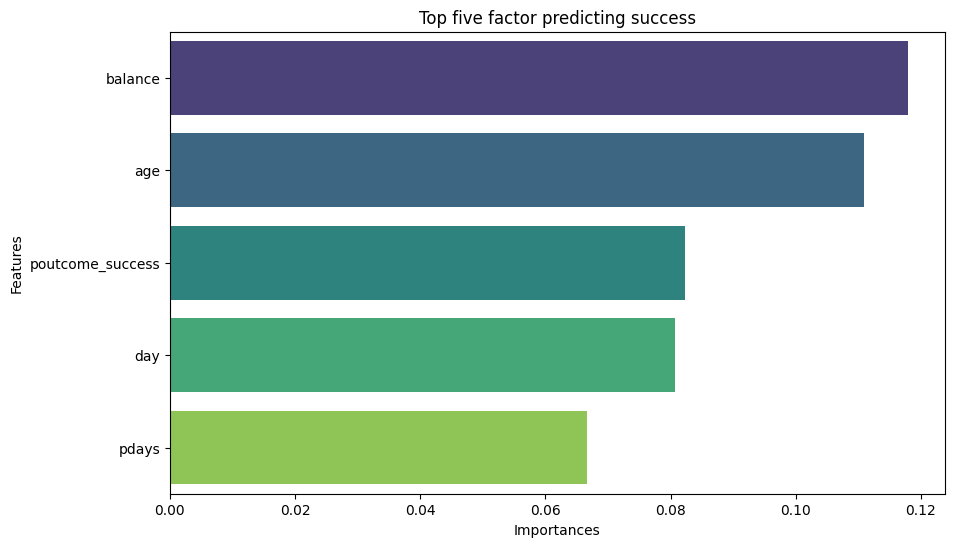

In [45]:
# to get featue importance

importances = best_rf.feature_importances_
feature_names = X.columns

feature_importance_df = pd.DataFrame({'Features': feature_names, 'Importances': importances})
feature_importance_df.sort_values('Importances', ascending= False).head(5)

plt.figure(figsize=(10,6))
sns.barplot(y='Features', x='Importances', data=feature_importance_df.sort_values('Importances', ascending=False).head(5), palette='viridis')
plt.title('Top five factor predicting success')
plt.show()

In [46]:
# Let save the model

import joblib

# to save a trained model to a file

joblib.dump(best_rf, 'best_rf_model.pkl')
joblib.dump(scalar, 'bank_scalar.pkl')

['bank_scalar.pkl']